In [42]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

In [18]:
# importar dataset CIFAR 10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

In [20]:
train_images, test_images = train_images /255.0, test_images/255.0
train_images[0].shape

(32, 32, 3)

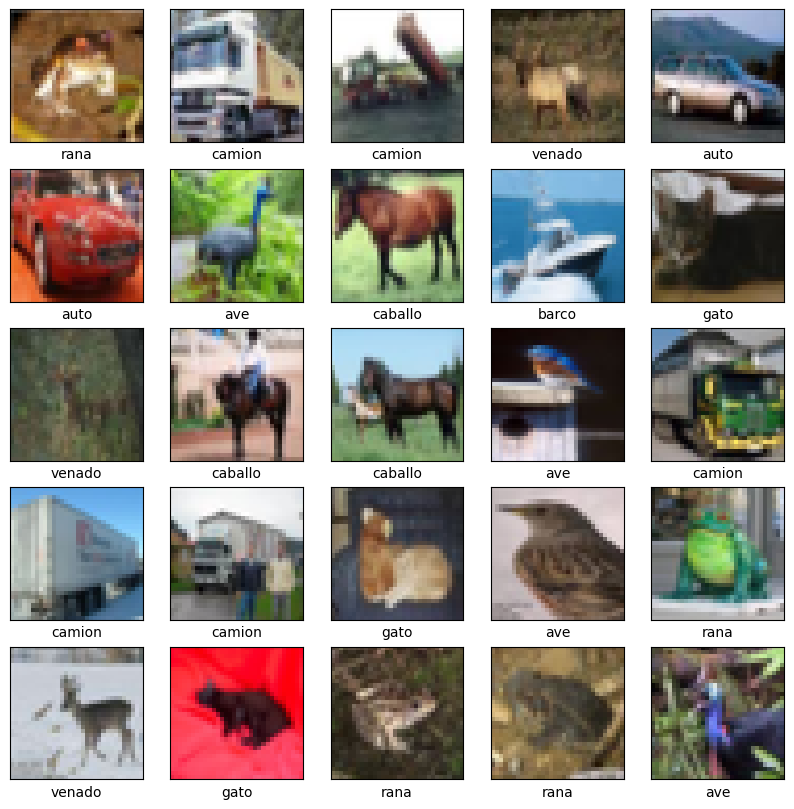

In [34]:
# Explorar el dataset
clases = ['avion', 'auto', 'ave', 'gato', 'venado', 'perro', 'rana', 'caballo','barco','camion']

plt.figure(figsize=(10,10))

for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(clases[train_labels[i][0]])
plt.show()

# Crear el modelo CNN

In [52]:
modelo = models.Sequential()

modelo.add(layers.Conv2D(32, (3,3), activation = "relu", input_shape = (32,32,3)))
modelo.add(layers.MaxPooling2D((2,2)))

modelo.add(layers.Conv2D(64, (3,3), activation = "relu"))
modelo.add(layers.MaxPooling2D((2,2)))
           
modelo.add(layers.Flatten())
           
modelo.add(layers.Dense(64, activation="relu"))
modelo.add(layers.Dense(10))

/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [54]:
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
modelo.compile(
    optimizer= "adam",
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics = ['accuracy']
)

In [60]:
historial = modelo.fit(
    train_images,
    train_labels,
    epochs = 20,
    validation_data =(test_images, test_labels)
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.3876 - loss: 1.6775 - val_accuracy: 0.5515 - val_loss: 1.2433
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6054 - loss: 1.1347 - val_accuracy: 0.6465 - val_loss: 1.0254
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.6605 - loss: 0.9790 - val_accuracy: 0.6560 - val_loss: 0.9854
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6938 - loss: 0.8891 - val_accuracy: 0.6686 - val_loss: 0.9610
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.7198 - loss: 0.8077 - val_accuracy: 0.6930 - val_loss: 0.8965
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7454 - loss: 0.7351 - val_accuracy: 0.6943 - val_loss: 0.9061
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7670 - loss: 0.6809 - val_accuracy: 0.7052 - val_loss: 0.8726
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7818 - los

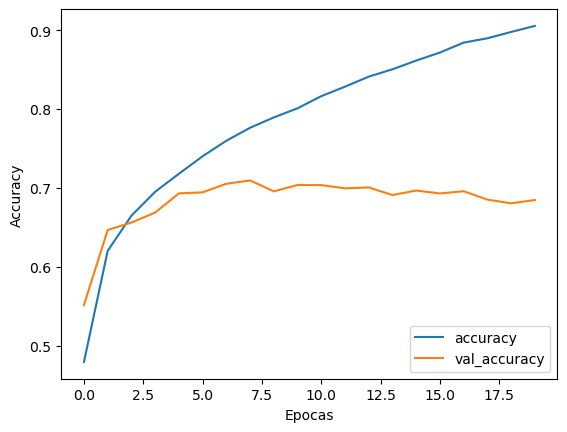

In [62]:
plt.plot(historial.history['accuracy'], label="accuracy")
plt.plot(historial.history['val_accuracy'], label="val_accuracy")
plt.xlabel("Epocas")
plt.ylabel("Accuracy")
plt.legend(loc='lower right')
plt.show()

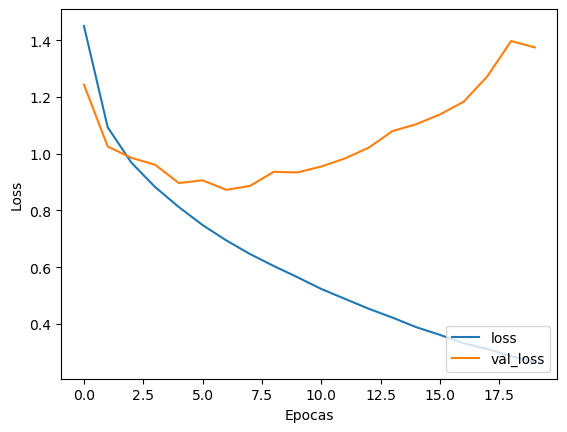

In [64]:
plt.plot(historial.history['loss'], label="loss")
plt.plot(historial.history['val_loss'], label="val_loss")
plt.xlabel("Epocas")
plt.ylabel("Loss")
plt.legend(loc='lower right')
plt.show()

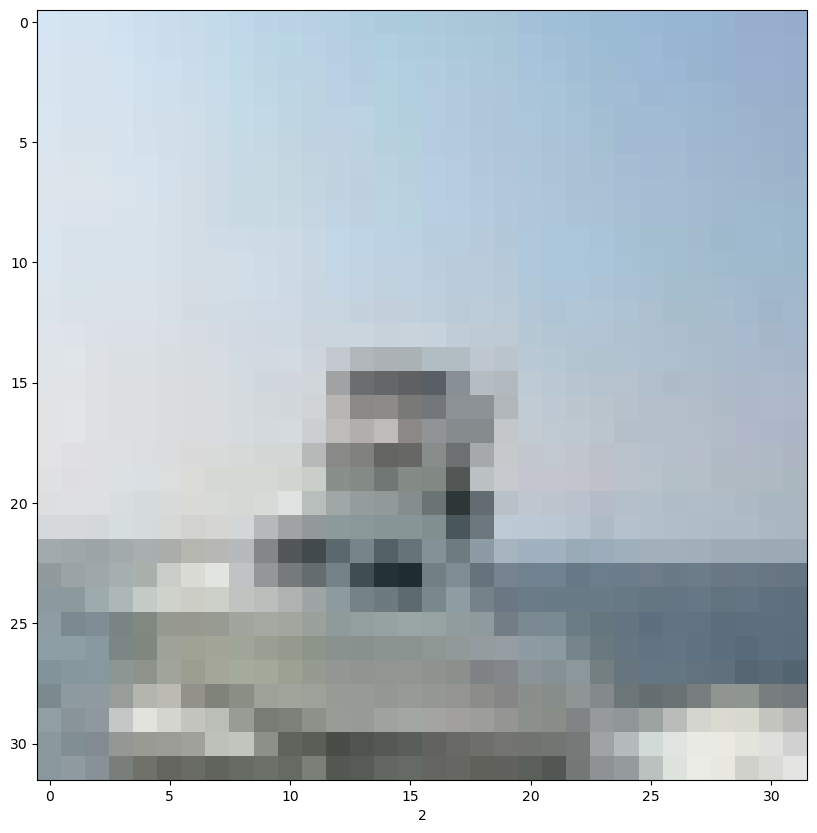

In [70]:
# Explorar el dataset
clases = ['avion', 'auto', 'ave', 'gato', 'venado', 'perro', 'rana', 'caballo','barco','camion']

plt.figure(figsize=(10,10))
plt.grid(False)
plt.imshow(train_images[100])
plt.xlabel(train_labels[i][0])
plt.show()

In [78]:
y_pred = modelo.predict(train_images[100])
print(y_pred)

ValueError: Exception encountered when calling Sequential.call().

[1mInvalid input shape for input Tensor("data:0", shape=(32, 32, 3), dtype=float32). Expected shape (None, 32, 32, 3), but input has incompatible shape (32, 32, 3)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(32, 32, 3), dtype=float32)
  • training=False
  • mask=None